# Headline CPI inflation: structural breaks and forecasting

Does headline CPI inflation change its behaviour around COVID-19 and the 2025 tariffs / Iran conflict, and does accounting for a break improve forecasts?

## Step 0 — Setup and data
Raw FRED pull from `data_memo.ipynb`: headline CPI (CPIAUCSL), monthly, seasonally adjusted.

In [170]:
"""
Project analysis: headline CPI inflation, structural breaks and forecasting.

Inputs : data/raw/fred_prices_raw.csv   raw FRED index levels saved by data_memo.ipynb
Outputs: tables and figures displayed inline in this notebook
"""
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import adfuller, kpss

# This notebook lives in code/, so the project root is one level up;
# the check also lets it run from the project root itself.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

# Raw FRED pull from data_memo.ipynb: monthly SA index levels, no transformation.
prices_raw = pd.read_csv(ROOT / "data" / "raw" / "fred_prices_raw.csv",
                         parse_dates=["date"], index_col="date")
cpi = prices_raw["CPIAUCSL"].dropna()
print(f"Headline CPI: {cpi.index.min():%Y-%m} to {cpi.index.max():%Y-%m}, {len(cpi)} obs")


def unit_root_tests(y, regression):
    """ADF and KPSS on `y` with the same deterministic spec ("c" or "ct").

    ADF (H0: unit root): lags chosen by AIC from p_max = 12(T/100)^(1/4) (Schwert rule).
    KPSS (H0: stationary): automatic bandwidth. Its p-values are bounded to [0.01, 0.10]
    by the lookup table, so a value at either bound means "at most" / "at least".
    """
    p_max = int(12 * (len(y) / 100) ** 0.25)
    adf_stat, adf_p, adf_lags, *_ = adfuller(y, regression=regression, maxlag=p_max, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_stat, kpss_p, kpss_lags, _ = kpss(y, regression=regression, nlags="auto")
    return {"ADF stat": adf_stat, "ADF p": adf_p, "ADF lags": adf_lags,
            "KPSS stat": kpss_stat, "KPSS p": kpss_p, "KPSS bandwidth": kpss_lags}


# Joint ADF/KPSS reading (Step 4 table): (ADF rejects?, KPSS rejects?) -> conclusion
JOINT_READING = {
    (True, False):  "stationary, I(0)",
    (False, True):  "unit root, I(1)",
    (True, True):   "near-integrated or structural break; investigate subsamples",
    (False, False): "inconclusive; rely on economic prior / larger sample",
}


SPEC_LABELS = {"ct": "Constant + trend", "c": "Constant only"}


def show_tests(tests, alpha=0.05):
    """Display ADF/KPSS results as a table, one row per spec, with the joint reading."""
    def kpss_p(p):
        return "<= 0.01" if p <= 0.01 else ">= 0.10" if p >= 0.10 else f"{p:.3f}"
    table = pd.DataFrame({
        "ADF stat": tests["ADF stat"].map("{:.2f}".format),
        "ADF p": tests["ADF p"].map("{:.3f}".format),
        "ADF lags": tests["ADF lags"].astype(int),
        "KPSS stat": tests["KPSS stat"].map("{:.3f}".format),
        "KPSS p": tests["KPSS p"].map(kpss_p),
        f"Conclusion ({alpha:.0%} level)": [JOINT_READING[(r["ADF p"] < alpha, r["KPSS p"] < alpha)]
                                         for _, r in tests.iterrows()],
    })
    display(table)


Headline CPI: 1947-01 to 2026-08, 955 obs


## Step 1 — Data preparation
- **Sample:** 1985-01 to 2026-08 (post-Great Moderation).
- **October 2025** (not collected, government shutdown): log-linear interpolation of the price level.
- **Train / test split:** train 1985-01 to 2023-12, hold out 2024-01 to 2026-08; fixed before any model selection.

In [171]:
import numpy as np

# Sample window: post-Great Moderation. Starting in 1985 keeps the 1970s-early 80s
# high-inflation regime from dominating the break tests; the fixed end date keeps
# results reproducible as FRED adds/revises data. Matches data_memo.ipynb.
SAMPLE_START, SAMPLE_END = "1985-01-01", "2026-08-01"
prices = prices_raw.loc[SAMPLE_START:SAMPLE_END].copy()

# October 2025 was not collected (federal government shutdown) for every CPI series
# except gasoline. Fill it log-linearly: ln P_Oct = (ln P_Sep + ln P_Nov) / 2, i.e. the
# Sep->Nov change is split evenly across the two months. Only interior gaps are filled.
missing = prices.isna()
prices = np.exp(np.log(prices).interpolate(method="linear", limit_area="inside"))
filled = missing & prices.notna()

print(f"Sample {SAMPLE_START[:7]} to {SAMPLE_END[:7]}: {len(prices)} months, "
      f"{prices.isna().sum().sum()} missing values remain")
print("Filled:", {k: [f"{d:%Y-%m}" for d in prices.index[filled[k]]] for k in prices if filled[k].any()})

# Train/test split, fixed before any model selection to avoid look-ahead bias.
# Model identification, estimation, diagnostics and IC comparison (Steps 6-9) use the
# training set only; the hold-out is touched only for forecast evaluation (Steps 11-12).
# COVID falls in training; the 2025 tariffs and the Iran conflict fall in the hold-out.
TRAIN_END, TEST_START = "2023-12-01", "2024-01-01"
train = prices.loc[:TRAIN_END]
test = prices.loc[TEST_START:]
print(f"Train {train.index.min():%Y-%m} to {train.index.max():%Y-%m}: {len(train)} months | "
      f"Test {test.index.min():%Y-%m} to {test.index.max():%Y-%m}: {len(test)} months")

prices.loc["2025-09":"2025-11", ["CPIAUCSL"]]

Sample 1985-01 to 2026-08: 500 months, 0 missing values remain
Filled: {'CPIAUCSL': ['2025-10'], 'CPILFESL': ['2025-10'], 'CPIUFDSL': ['2025-10'], 'CUSR0000SAF11': ['2025-10'], 'CPIENGSL': ['2025-10'], 'CUSR0000SEHF': ['2025-10'], 'CUSR0000SEHF01': ['2025-10']}
Train 1985-01 to 2023-12: 468 months | Test 2024-01 to 2026-08: 32 months


,CPIAUCSL
date,
2025-09-01,324.245000
2025-10-01,324.653742
2025-11-01,325.063000


## Step 2 — Visualization
Raw price level (full history) and its ACF / PACF (training set), with ADF / KPSS results.

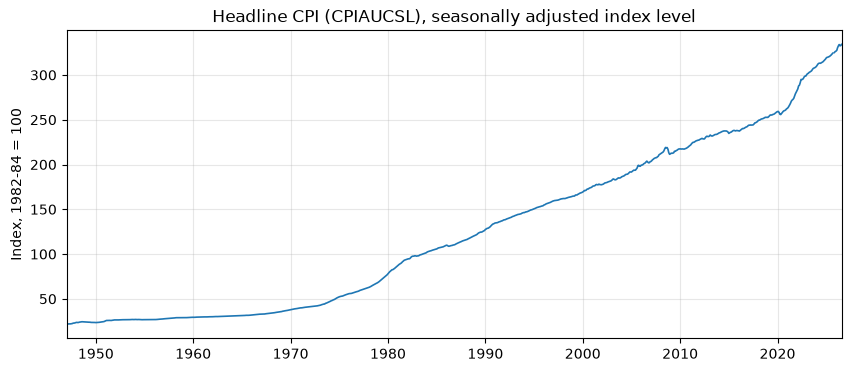

In [172]:
# Headline CPI, raw index level (1982-84 = 100). Plotted from the unfiltered column
# so the missing October 2025 observation shows as a break in the line.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prices_raw.index, prices_raw["CPIAUCSL"], lw=1.2)
ax.set_title("Headline CPI (CPIAUCSL), seasonally adjusted index level")
ax.set_ylabel("Index, 1982-84 = 100")
ax.set_xlim(cpi.index.min(), cpi.index.max())
ax.grid(alpha=0.3)
plt.show()

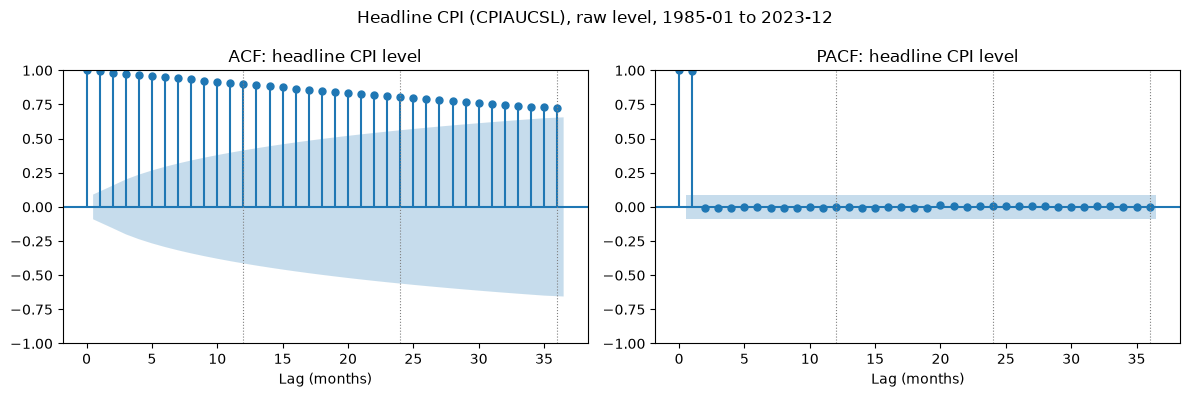

,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,Conclusion (5% level)
Deterministic spec,,,,,,
Constant + trend,-1.74,0.733,15,0.197,0.017,"unit root, I(1)"
Constant only,1.07,0.995,15,3.647,<= 0.01,"unit root, I(1)"


In [173]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Sample ACF / PACF of the headline CPI level, training set only (no look-ahead into
# the hold-out). Out to lag 36 to cover seasonal lags 12, 24, 36. A slow, near-linear
# ACF decay with a single PACF spike at lag 1 is the signature of a unit root.
cpi_train = train["CPIAUCSL"]

# Raw level has a clear upward trend, so constant + trend ("ct") is the main spec;
# constant-only ("c") is shown for comparison. Full discussion in Step 4.
level_tests = pd.DataFrame(
    {SPEC_LABELS[spec]: unit_root_tests(cpi_train, spec) for spec in ("ct", "c")}
).T.rename_axis("Deterministic spec")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(cpi_train, lags=36, ax=axes[0], title="ACF: headline CPI level")
plot_pacf(cpi_train, lags=36, ax=axes[1], method="ywm", title="PACF: headline CPI level")
for ax in axes:
    for lag in (12, 24, 36):
        ax.axvline(lag, color="gray", ls=":", lw=0.8)
    ax.set_xlabel("Lag (months)")
fig.suptitle(f"Headline CPI (CPIAUCSL), raw level, {cpi_train.index.min():%Y-%m} to {cpi_train.index.max():%Y-%m}")
fig.tight_layout()
plt.show()
show_tests(level_tests)

## Step 3 — Transformation
Annualized monthly inflation, π<sub>t</sub> = 1200 · Δln CPI<sub>t</sub>, removes the unit root in the level.

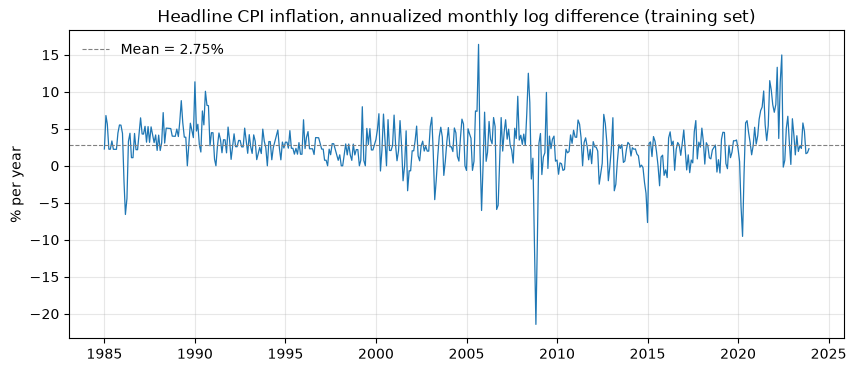

,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,Conclusion (5% level)
Deterministic spec,,,,,,
Constant only,-3.88,0.002,14,0.353,0.097,"stationary, I(0)"
Constant + trend,-3.95,0.010,14,0.221,<= 0.01,near-integrated or structural break; investiga...


In [174]:
# Annualized monthly inflation: pi_t = 1200 * (ln P_t - ln P_{t-1}), % per year.
# Log first difference removes the stochastic trend (unit root) found in Step 4 and is
# ~ the monthly growth rate; x1200 only rescales units. Dec 1984 is prepended from the raw
# file so Jan 1985 keeps a value. Matches "ann" in data_memo.ipynb.
log_prices = np.log(pd.concat([prices_raw.loc[["1984-12-01"]], prices]))
infl = (1200 * log_prices.diff()).loc[SAMPLE_START:].asfreq("MS")  # monthly freq for statsmodels
infl_train, infl_test = infl.loc[:TRAIN_END], infl.loc[TEST_START:]
pi_train = infl_train["CPIAUCSL"]

# Inflation shows no trend but a nonzero mean, so constant-only ("c") is the main spec;
# constant + trend ("ct") is shown for comparison. Full discussion in Step 4.
diff_tests = pd.DataFrame(
    {SPEC_LABELS[spec]: unit_root_tests(pi_train, spec) for spec in ("c", "ct")}
).T.rename_axis("Deterministic spec")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pi_train.index, pi_train, lw=0.9)
ax.axhline(pi_train.mean(), color="gray", ls="--", lw=0.8, label=f"Mean = {pi_train.mean():.2f}%")
ax.set_title("Headline CPI inflation, annualized monthly log difference (training set)")
ax.set_ylabel("% per year")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()
show_tests(diff_tests)

## Step 4 — Stationarity
Level is I(1); inflation is I(0), so d = 1 on the price level (d = 0 on inflation).

In [175]:
# ADF / KPSS results for headline CPI, training set (computed alongside the Step 2 and
# Step 3 graphs). Level: ADF fails to reject, KPSS rejects -> unit root, I(1).
# First log difference: ADF rejects, KPSS fails to reject at 5% -> I(0), so d = 1.
unit_root_summary = pd.concat(
    {"Level": level_tests, "Δ ln (annualized)": diff_tests}, names=["Series"]
)
unit_root_summary.round(3)

ADF stat  ADF p  ADF lags  KPSS stat  \
Series            Deterministic spec                                         
Level             Constant + trend      -1.741  0.733      15.0      0.197   
                  Constant only          1.070  0.995      15.0      3.647   
Δ ln (annualized) Constant only         -3.878  0.002      14.0      0.353   
                  Constant + trend      -3.947  0.010      14.0      0.221   

                                      KPSS p  KPSS bandwidth  
Series            Deterministic spec                          
Level             Constant + trend     0.017            12.0  
                  Constant only        0.010            12.0  
Δ ln (annualized) Constant only        0.097             7.0  
                  Constant + trend     0.010             7.0

## Step 5 — Seasonality and ACF / PACF of inflation
No spikes at seasonal lags 12 / 24 / 36 (series is seasonally adjusted), so D = 0.

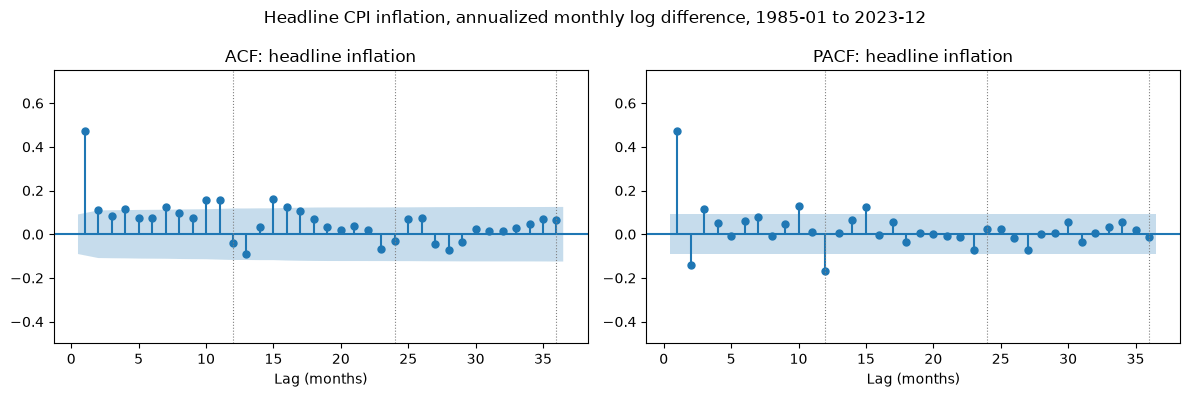

In [176]:
# Sample ACF / PACF of headline inflation (first log difference), training set.
# Serves Step 5 (spikes at seasonal lags 12, 24, 36 would mean residual seasonality)
# and Step 6 (cut-off vs. tail-off pattern suggests candidate AR / MA orders).
# zero=False drops the lag-0 bar, which is always 1 and carries no information.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(pi_train, lags=36, zero=False, ax=axes[0], title="ACF: headline inflation")
plot_pacf(pi_train, lags=36, zero=False, ax=axes[1], method="ywm", title="PACF: headline inflation")
for ax in axes:
    for lag in (12, 24, 36):
        ax.axvline(lag, color="gray", ls=":", lw=0.8)
    ax.set_xlabel("Lag (months)")
    ax.set_ylim(-0.5, 0.75)
fig.suptitle(f"Headline CPI inflation, annualized monthly log difference, "
             f"{pi_train.index.min():%Y-%m} to {pi_train.index.max():%Y-%m}")
fig.tight_layout()
plt.show()

## Step 6 — Candidate models

In [177]:
# Candidate models from the inflation ACF / PACF (Step 5 plots), as
# name -> (order (p, d, q), seasonal_order (P, D, Q, s)). d = 0: inflation is already I(0).
#   AR(1)            PACF spike at lag 1, ACF tails off
#   AR(2), AR(3)     smaller PACF spikes at lags 2 and 3
#   ARMA(1,1)        ACF tail longer / flatter than a pure AR(1) implies
#   ARMA(1,1)xSMA(1) PACF spike at lag 12 (likely seasonal-adjustment residue)
CANDIDATES = {
    "AR(1)":            ((1, 0, 0), (0, 0, 0, 0)),
    "AR(2)":            ((2, 0, 0), (0, 0, 0, 0)),
    "AR(3)":            ((3, 0, 0), (0, 0, 0, 0)),
    "ARMA(1,1)":        ((1, 0, 1), (0, 0, 0, 0)),
    "ARMA(1,1)xSMA(1)": ((1, 0, 1), (0, 0, 1, 12)),
}

## Step 7 — Estimation
All candidates by MLE on the training set: coefficients, information criteria, residual diagnostics.

In [178]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.arima.model import ARIMA

# MLE on the training set, constant included (inflation has a nonzero mean).
# Same sample, same d, same dependent variable for every model, so ICs are comparable.
fits = {
    name: ARIMA(pi_train, order=order, seasonal_order=seasonal, trend="c").fit()
    for name, (order, seasonal) in CANDIDATES.items()
}


def diagnostics(res, n_arma, burn=13):
    """Residual-diagnostic p-values (small = problem) for a fitted model.

    The first `burn` residuals are dropped for every model (start-up effects; 13 covers
    the seasonal model's lag-12 + lag-1 terms), keeping the comparison even.
    Ljung-Box df is reduced by the number of ARMA terms `n_arma`.
    """
    e = res.resid.iloc[burn:]
    lb = acorr_ljungbox(e, lags=[12, 24], model_df=n_arma)
    return {
        "Ljung-Box(12) p": lb.loc[12, "lb_pvalue"],
        "Ljung-Box(24) p": lb.loc[24, "lb_pvalue"],
        "Jarque-Bera p": jarque_bera(e)[1],
        "ARCH-LM(12) p": het_arch(e, nlags=12)[1],
    }


# One comparison table: coefficients "estimate (p-value)", then fit statistics
# (lower AIC / BIC / HQIC is better), then residual diagnostics (Step 8).
coef_table = pd.DataFrame({
    name: {k: f"{b:.3f} ({res.pvalues[k]:.3f})" for k, b in res.params.items()}
    for name, res in fits.items()
})
coef_table = coef_table.loc[["const", "sigma2"] + [k for k in coef_table.index if k not in ("const", "sigma2")]]
fit_table = pd.DataFrame({
    name: {"Log-lik": res.llf, "AIC": res.aic, "BIC": res.bic, "HQIC": res.hqic}
    for name, res in fits.items()
}).map("{:.1f}".format)
diag_table = pd.DataFrame({
    name: diagnostics(res, n_arma=sum(order[::2]) + sum(seasonal[:3:2]))
    for (name, res), (order, seasonal) in zip(fits.items(), CANDIDATES.values())
}).map("{:.3f}".format)
model_table = pd.concat(
    {"Coefficients": coef_table, "Fit": fit_table, "Residual diagnostics (p)": diag_table},
    names=["Block", "Statistic"],
).fillna("")
model_table

AR(1)           AR(2)  \
Block                    Statistic                                        
Coefficients             const            2.752 (0.000)   2.750 (0.000)   
                         sigma2           8.100 (0.000)   7.936 (0.000)   
                         ar.L1            0.471 (0.000)   0.538 (0.000)   
                         ar.L2                           -0.142 (0.000)   
                         ar.L3                                            
                         ma.L1                                            
                         ma.S.L12                                         
Fit                      Log-lik                -1153.7         -1148.9   
                         AIC                     2313.4          2305.9   
                         BIC                     2325.8          2322.4   
                         HQIC                    2318.3          2312.4   
Residual diagnostics (p) Ljung-Box(12) p          0.000           0.000   
                         Ljung-Box(24) p          0.000           0.000   
                         Jarque-Bera p            0.000           0.000   
                         ARCH-LM(12) p            0.000           0.000   

                                                   AR(3)      ARMA(1,1)  \
Block                    Statistic                                        
Coefficients             const             2.751 (0.000)  2.751 (0.000)   
                         sigma2            7.827 (0.000)  7.880 (0.000)   
                         ar.L1             0.555 (0.000)  0.210 (0.002)   
                         ar.L2            -0.205 (0.000)                  
                         ar.L3             0.117 (0.003)                  
                         ma.L1                            0.344 (0.000)   
                         ma.S.L12                                         
Fit                      Log-lik                 -1145.7        -1147.3   
                         AIC                      2301.4         2302.5   
                         BIC                      2322.2         2319.1   
                         HQIC                     2309.6         2309.1   
Residual diagnostics (p) Ljung-Box(12) p           0.006          0.001   
                         Ljung-Box(24) p           0.002          0.000   
                         Jarque-Bera p             0.000          0.000   
                         ARCH-LM(12) p             0.000          0.000   

                                         ARMA(1,1)xSMA(1)  
Block                    Statistic                         
Coefficients             const              2.746 (0.000)  
                         sigma2             7.803 (0.000)  
                         ar.L1              0.231 (0.000)  
                         ar.L2                             
                         ar.L3                             
                         ma.L1              0.333 (0.000)  
                         ma.S.L12          -0.100 (0.018)  
Fit                      Log-lik                  -1145.0  
                         AIC                       2300.1  
                         BIC                       2320.8  
                         HQIC                      2308.2  
Residual diagnostics (p) Ljung-Box(12) p            0.001  
                         Ljung-Box(24) p            0.001  
                         Jarque-Bera p              0.000  
                         ARCH-LM(12) p              0.000

## Step 8 — Diagnostics for the selected model, ARMA(1,1)

In [179]:
# Full residual diagnostics for the selected model, ARMA(1,1): chosen in Step 9 on BIC and
# parsimony (AIC / HQIC favour the seasonal variant by < 2 points, diagnostics no better).
best_name = "ARMA(1,1)"
best = fits[best_name]
e = best.resid.iloc[13:]  # same burn-in as the Step 7 comparison table
alpha = 0.05

lb = acorr_ljungbox(e, lags=[6, 12, 24], model_df=2)
jb_stat, jb_p, skew, kurt = jarque_bera(e)
arch_stat, arch_p, *_ = het_arch(e, nlags=12)
h_stat, h_p = best.test_heteroskedasticity("breakvar")[0]  # Harvey H: last third vs. first third

rows = [
    *[(f"Ljung-Box({lag})", "Serial correlation", f"No autocorrelation up to lag {lag}",
       lb.loc[lag, "lb_stat"], lb.loc[lag, "lb_pvalue"]) for lag in (6, 12, 24)],
    ("Jarque-Bera", "Normality", f"Normal (skew = {skew:.2f}, kurtosis = {kurt:.1f})", jb_stat, jb_p),
    ("ARCH-LM(12)", "Volatility clustering", "No ARCH effects", arch_stat, arch_p),
    ("Harvey H", "Homoskedasticity", "Equal variance, first vs. last third", h_stat, h_p),
]
diag_best = pd.DataFrame(rows, columns=["Test", "Checks", "H0", "Statistic", "p-value"]).set_index("Test")
diag_best["Result (5%)"] = np.where(diag_best["p-value"] < alpha, "Reject H0 (fails)", "Pass")
display(diag_best.style.format({"Statistic": "{:.2f}", "p-value": "{:.3f}"}))

# Stability: AR roots outside the unit circle -> stationary; MA roots outside -> invertible.
# AR and MA roots far apart -> no near-cancellation (no common-factor redundancy).
roots = pd.DataFrame({
    "Root": [*best.arroots, *best.maroots],
    "Modulus": [*abs(best.arroots), *abs(best.maroots)],
}, index=["AR root"] * len(best.arroots) + ["MA root"] * len(best.maroots))
roots["Outside unit circle"] = roots["Modulus"] > 1
roots.style.format({"Root": "{:.3f}", "Modulus": "{:.3f}"})

,Checks,H0,Statistic,p-value,Result (5%)
Test,,,,,
Ljung-Box(6),Serial correlation,No autocorrelation up to lag 6,5.01,0.286,Pass
Ljung-Box(12),Serial correlation,No autocorrelation up to lag 12,29.61,0.001,Reject H0 (fails)
Ljung-Box(24),Serial correlation,No autocorrelation up to lag 24,51.43,0.000,Reject H0 (fails)
Jarque-Bera,Normality,"Normal (skew = -0.54, kurtosis = 7.9)",472.74,0.000,Reject H0 (fails)
ARCH-LM(12),Volatility clustering,No ARCH effects,67.76,0.000,Reject H0 (fails)
Harvey H,Homoskedasticity,"Equal variance, first vs. last third",2.01,0.000,Reject H0 (fails)


,Root,Modulus,Outside unit circle
AR root,4.759,4.759,True
MA root,-2.908,2.908,True


## Step 9 — Model selection
ARMA(1,1): best BIC; AIC / HQIC favour the seasonal variant by < 2.5 points with no better diagnostics, so the more parsimonious model is kept.

In [180]:
# Model selection. ICs are comparable here: same training sample, same d = 0, same
# dependent variable, same model family (Step 9 rules). Δ = distance from the best model
# on each criterion (0 = best); differences under ~2 are weak evidence either way.
ic = pd.DataFrame({
    name: {"Params": len(res.params), "AIC": res.aic, "BIC": res.bic, "HQIC": res.hqic}
    for name, res in fits.items()
}).T
for crit in ("AIC", "BIC", "HQIC"):
    ic[f"Δ{crit}"] = ic[crit] - ic[crit].min()

# Residual autocorrelation at a short (6) and long (24) horizon, p-values (small = fails)
n_arma = {name: sum(o[::2]) + sum(sea[:3:2]) for name, (o, sea) in CANDIDATES.items()}
for lag in (6, 24):
    ic[f"Ljung-Box({lag}) p"] = [
        acorr_ljungbox(res.resid.iloc[13:], lags=[lag], model_df=n_arma[name])["lb_pvalue"].iloc[0]
        for name, res in fits.items()
    ]
ic["Selected"] = np.where(ic.index == best_name, "✓", "")

display(ic.style
        .format({"Params": "{:.0f}", "Ljung-Box(6) p": "{:.3f}", "Ljung-Box(24) p": "{:.3f}",
                 **{col: "{:.1f}" for col in ic.columns if col.endswith(("AIC", "BIC", "HQIC"))}})
        .highlight_min(subset=["AIC", "BIC", "HQIC"], props="font-weight: bold"))

# Which model each criterion picks, and how far the selected model is from it
picks = pd.DataFrame({
    "Picks": {crit: ic[crit].idxmin() for crit in ("AIC", "BIC", "HQIC")},
    f"{best_name} gap": {crit: ic.loc[best_name, f"Δ{crit}"] for crit in ("AIC", "BIC", "HQIC")},
}).rename_axis("Criterion")
picks.style.format({f"{best_name} gap": "{:.1f}"})

,Params,AIC,BIC,HQIC,ΔAIC,ΔBIC,ΔHQIC,Ljung-Box(6) p,Ljung-Box(24) p,Selected
AR(1),3,2313.4,2325.8,2318.3,13.3,6.7,10.0,0.004,0.000,
AR(2),4,2305.9,2322.4,2312.4,5.8,3.3,4.1,0.063,0.000,
AR(3),5,2301.4,2322.2,2309.6,1.3,3.0,1.3,0.730,0.002,
"ARMA(1,1)",4,2302.5,2319.1,2309.1,2.5,0.0,0.8,0.286,0.000,✓
"ARMA(1,1)xSMA(1)",5,2300.1,2320.8,2308.2,0.0,1.7,0.0,0.095,0.001,


,Picks,"ARMA(1,1) gap"
Criterion,,
AIC,"ARMA(1,1)xSMA(1)",2.5
BIC,"ARMA(1,1)",0.0
HQIC,"ARMA(1,1)xSMA(1)",0.8


## Step 10 — Structural break tests
Full sample 1985-01 to 2026-08, HAC standard errors (residuals are heteroskedastic).

In [181]:
import statsmodels.api as sm
from scipy import stats

# Structural break tests on headline inflation, FULL sample 1985-01 to 2026-08. In-sample
# break testing may use the hold-out months (only forecasting must not); this is what lets
# the 2025 dates be tested at all. The tariffs (2025-04) and the Iran conflict (2025-06)
# are two months apart, so the data cannot tell them apart: one 2025 date is tested.
# Errors are heteroskedastic (Step 8: ARCH-LM, Harvey H fail), so every coefficient test
# uses HAC (Newey-West, 12 lags) standard errors instead of the classic F.
BREAK_DATES = {"COVID-19": "2020-03-01", "2025 tariffs / Iran": "2025-04-01"}
HAC = {"cov_type": "HAC", "cov_kwds": {"maxlags": 12}}

pi_full = infl["CPIAUCSL"]
reg = pd.DataFrame({"pi": pi_full, "pi_lag": pi_full.shift(1)}).dropna()  # AR(1) regression data


def chow_tests(date):
    """Known-date tests at `date`: mean shift, persistence change (Chow), variance ratio."""
    D = (reg.index >= date).astype(float)
    X = pd.DataFrame({"const": 1.0, "pi_lag": reg["pi_lag"], "D": D, "D_x_lag": D * reg["pi_lag"]},
                     index=reg.index)
    # Mean shift: pi_t = a + c*D_t + e_t (constant-only regression, as in L3)
    mean_fit = sm.OLS(reg["pi"], X[["const", "D"]]).fit(**HAC)
    # Chow, dummy-interaction form: pi_t = a + b*pi_{t-1} + c*D_t + d*D_t*pi_{t-1} + e_t
    chow_fit = sm.OLS(reg["pi"], X).fit(**HAC)
    chow = chow_fit.wald_test("D = 0, D_x_lag = 0", scalar=True)
    # Variance ratio F on the AR(1) residuals with no break: post / pre
    e = sm.OLS(reg["pi"], X[["const", "pi_lag"]]).fit().resid
    pre, post = e[D == 0], e[D == 1]
    f = post.var() / pre.var()
    f_p = 2 * min(stats.f.cdf(f, len(post) - 1, len(pre) - 1), stats.f.sf(f, len(post) - 1, len(pre) - 1))
    return {
        "Months after": int(D.sum()),
        "Mean before": reg["pi"][D == 0].mean(), "Mean after": reg["pi"][D == 1].mean(),
        "Mean shift p": mean_fit.pvalues["D"],
        "AR(1) before": chow_fit.params["pi_lag"],
        "AR(1) after": chow_fit.params["pi_lag"] + chow_fit.params["D_x_lag"],
        "Persistence change p": chow_fit.pvalues["D_x_lag"],
        "Chow Wald": chow.statistic, "Chow p": chow.pvalue,
        "Variance ratio (after/before)": f, "Variance ratio p": f_p,
    }


known_breaks = pd.DataFrame({name: chow_tests(d) for name, d in BREAK_DATES.items()}).T
known_breaks.style.format("{:.3f}").format({"Months after": "{:.0f}"})

,Months after,Mean before,Mean after,Mean shift p,AR(1) before,AR(1) after,Persistence change p,Chow Wald,Chow p,Variance ratio (after/before),Variance ratio p
COVID-19,78,2.557305,3.903697,0.102296,0.436827,0.507705,0.581255,3.628568,0.162955,1.468041,0.020125
2025 tariffs / Iran,17,2.756126,3.097711,0.463410,0.472713,0.263473,0.039320,8.356271,0.015327,1.276163,0.415210


,sup-Wald,Break date,CV 10%,CV 5%,CV 1%,Significant at 5%
Mean shift,6.571794,1992-01,7.12,8.68,12.16,False
Chow (mean + persistence),8.096664,2008-10,10.0,11.72,15.56,False


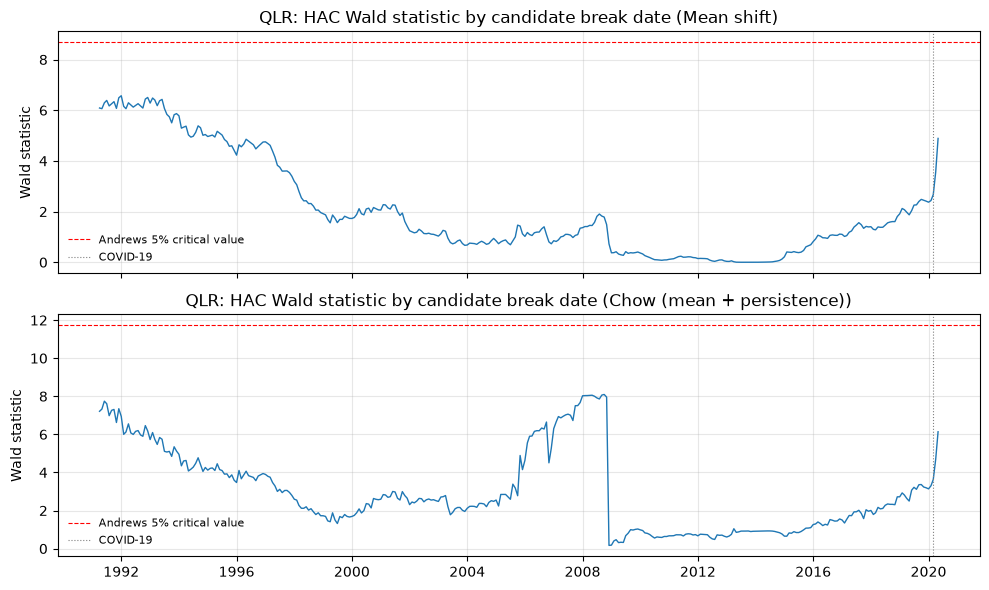

In [182]:
# Unknown break date: QLR / sup-Wald (Andrews 1993), 15% trimming. The HAC Wald statistic
# is computed at every candidate date; its maximum is compared with Andrews' critical values
# (not the usual chi-square / F ones). With 15% trimming the last candidate date is
# 2020-05, so COVID is testable but the 2025 dates fall outside the search window.
ANDREWS_CV = {1: {"10%": 7.12, "5%": 8.68, "1%": 12.16},   # q = 1 restriction (mean)
              2: {"10%": 10.00, "5%": 11.72, "1%": 15.56}}  # q = 2 restrictions (Chow)
trim = 0.15
n = len(reg)
candidates = reg.index[int(trim * n):int((1 - trim) * n)]


def wald_path(date):
    D = (reg.index >= date).astype(float)
    X = pd.DataFrame({"const": 1.0, "pi_lag": reg["pi_lag"], "D": D, "D_x_lag": D * reg["pi_lag"]},
                     index=reg.index)
    mean_w = sm.OLS(reg["pi"], X[["const", "D"]]).fit(**HAC).tvalues["D"] ** 2
    chow_w = sm.OLS(reg["pi"], X).fit(**HAC).wald_test("D = 0, D_x_lag = 0", scalar=True).statistic
    return mean_w, chow_w


qlr_path = pd.DataFrame([wald_path(d) for d in candidates], index=candidates,
                        columns=["Mean shift", "Chow (mean + persistence)"])

qlr_table = pd.DataFrame({
    name: {"sup-Wald": qlr_path[name].max(), "Break date": f"{qlr_path[name].idxmax():%Y-%m}",
           **{f"CV {k}": v for k, v in ANDREWS_CV[q].items()},
           "Significant at 5%": qlr_path[name].max() > ANDREWS_CV[q]["5%"]}
    for name, q in (("Mean shift", 1), ("Chow (mean + persistence)", 2))
}).T
display(qlr_table)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (name, q) in zip(axes, (("Mean shift", 1), ("Chow (mean + persistence)", 2))):
    ax.plot(qlr_path.index, qlr_path[name], lw=1)
    ax.axhline(ANDREWS_CV[q]["5%"], color="red", ls="--", lw=0.8, label="Andrews 5% critical value")
    ax.axvline(pd.Timestamp(BREAK_DATES["COVID-19"]), color="gray", ls=":", lw=0.8, label="COVID-19")
    ax.set_title(f"QLR: HAC Wald statistic by candidate break date ({name})")
    ax.set_ylabel("Wald statistic")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [183]:
# Subperiod estimation of the selected ARMA(1,1) (Step 10 "ways to respond", option 1):
# compare mean, persistence, MA term and shock variance across regimes. The likelihood-ratio
# test asks whether one set of parameters fits both regimes: LR = 2(llf_pre + llf_post - llf_full),
# chi-square with 4 df (const, ar.L1, ma.L1, sigma2 all allowed to change).
regime_fits = {
    "Full sample": ARIMA(pi_full, order=(1, 0, 1), trend="c").fit(),
    "Pre-COVID": ARIMA(pi_full.loc[:"2020-02"], order=(1, 0, 1), trend="c").fit(),
    "Post-COVID": ARIMA(pi_full.loc["2020-03":], order=(1, 0, 1), trend="c").fit(),
}
regime_table = pd.DataFrame({
    name: {"Start": f"{res.model.data.row_labels[0]:%Y-%m}", "Months": int(res.nobs),
           "Mean (const)": res.params["const"], "ar.L1": res.params["ar.L1"], "ma.L1": res.params["ma.L1"],
           "1-month shock pass-through (ar + ma)": res.params["ar.L1"] + res.params["ma.L1"],
           "sigma2": res.params["sigma2"]}
    for name, res in regime_fits.items()
}).T
display(regime_table)

lr = 2 * (regime_fits["Pre-COVID"].llf + regime_fits["Post-COVID"].llf - regime_fits["Full sample"].llf)
print(f"LR test, one ARMA(1,1) for both regimes: LR = {lr:.2f}, df = 4, p = {stats.chi2.sf(lr, 4):.4f}")

,Start,Months,Mean (const),ar.L1,ma.L1,1-month shock pass-through (ar + ma),sigma2
Full sample,1985-01,500,2.766802,0.203802,0.343999,0.547801,7.74493
Pre-COVID,1985-01,422,2.551947,0.178973,0.332079,0.511052,7.160945
Post-COVID,2020-03,78,3.867401,-0.00928,0.656202,0.646922,10.166689


LR test, one ARMA(1,1) for both regimes: LR = 11.33, df = 4, p = 0.0230


## Step 11 — Forecasting
ARMA(1,1) vs. ARMA(1,1) with a COVID mean-shift dummy, estimated on the training set, forecasting the 2024-01 to 2026-08 hold-out.

In [184]:
# Forecast the hold-out (2024-01 to 2026-08) with models estimated on the training set only.
#   ARMA(1,1)            selected baseline (Step 9)
#   ARMA(1,1) + COVID    break-aware: mean-shift dummy D_t = 1 from 2020-03 (Step 10, option 2);
#                        the dummy stays 1 through the hold-out
# Parameters are fixed at their training estimates (no re-estimation in this step).
covid = BREAK_DATES["COVID-19"]
D_train = pd.Series((pi_train.index >= covid).astype(float), index=pi_train.index, name="COVID")
D_full = pd.Series((pi_full.index >= covid).astype(float), index=pi_full.index, name="COVID")

fc_models = {
    "ARMA(1,1)": fits[best_name],
    "ARMA(1,1) + COVID": ARIMA(pi_train, exog=D_train, order=(1, 0, 1), trend="c").fit(),
}
fc_exog = {"ARMA(1,1)": None, "ARMA(1,1) + COVID": D_full}

print(fc_models["ARMA(1,1) + COVID"].summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5659      0.240     10.675      0.000       2.095       3.037
COVID          1.8661      0.527      3.542      0.000       0.834       2.899
ar.L1          0.1670      0.072      2.316      0.021       0.026       0.308
ma.L1          0.3687      0.066      5.603      0.000       0.240       0.498
sigma2         7.7674      0.304     25.548      0.000       7.171       8.363


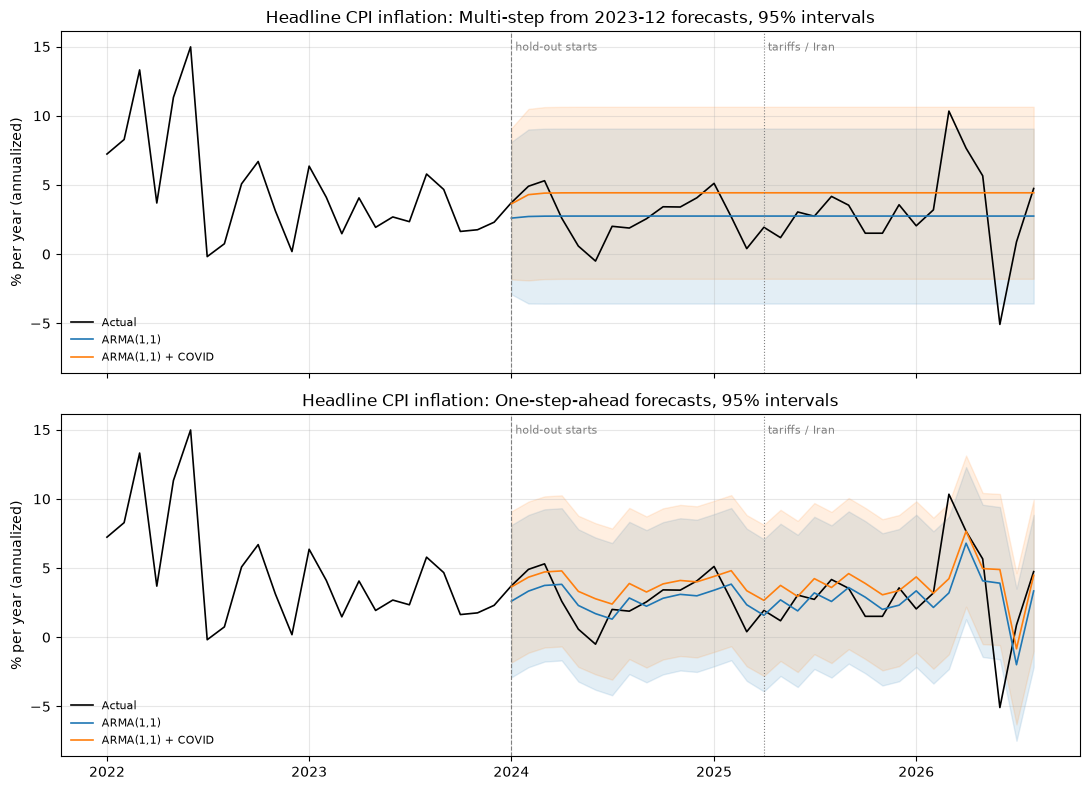

,"ARMA(1,1), multi-step","ARMA(1,1) + COVID, multi-step","ARMA(1,1), one-step","ARMA(1,1) + COVID, one-step",Actual
2024-01,2.60,3.63,2.60,3.63,3.71
2024-02,2.72,4.30,3.34,4.34,4.91
2024-03,2.74,4.41,3.74,4.72,5.31
2024-04,2.75,4.43,3.82,4.79,2.60
2024-05,2.75,4.43,2.30,3.32,0.58
2024-06,2.75,4.43,1.70,2.78,-0.50
2024-07,2.75,4.43,1.31,2.40,2.01
2024-08,2.75,4.43,2.84,3.89,1.89
2024-09,2.75,4.43,2.24,3.27,2.56
2024-10,2.75,4.43,2.82,3.86,3.42


In [185]:
# Two kinds of forecast over the hold-out (h = 32 months):
#   Multi-step: everything forecast from 2023-12 (h = 1, ..., 32), as if made at the cut-off.
#     An ARMA(1,1) forecast reverts to its mean within a few months, so this is mostly a
#     test of the mean.
#   One-step-ahead: each month forecast from the actual data through the month before,
#     with parameters fixed at the training estimates.
h = len(pi_full.loc[TEST_START:])
actual = pi_full.loc[TEST_START:]

multi, one_step = {}, {}
for name, res in fc_models.items():
    exog = fc_exog[name]
    exog_test = None if exog is None else exog.loc[TEST_START:]
    multi[name] = res.get_forecast(steps=h, exog=exog_test).summary_frame(alpha=0.05)
    applied = res.apply(pi_full, exog=exog, refit=False)  # same parameters, data through 2026-08
    one_step[name] = applied.get_prediction(start=TEST_START).summary_frame(alpha=0.05)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, (title, fcs) in zip(axes, (("Multi-step from 2023-12", multi), ("One-step-ahead", one_step))):
    ax.plot(pi_full.loc["2022-01":].index, pi_full.loc["2022-01":], color="black", lw=1.2, label="Actual")
    for (name, f), color in zip(fcs.items(), ("C0", "C1")):
        ax.plot(f.index, f["mean"], color=color, lw=1.2, label=name)
        ax.fill_between(f.index, f["mean_ci_lower"], f["mean_ci_upper"], color=color, alpha=0.12)
    ax.axvline(pd.Timestamp(TEST_START), color="gray", ls="--", lw=0.8)
    ax.axvline(pd.Timestamp(BREAK_DATES["2025 tariffs / Iran"]), color="gray", ls=":", lw=0.8)
    ax.text(pd.Timestamp(TEST_START), 0.97, " hold-out starts", transform=ax.get_xaxis_transform(),
            va="top", fontsize=8, color="gray")
    ax.text(pd.Timestamp(BREAK_DATES["2025 tariffs / Iran"]), 0.97, " tariffs / Iran",
            transform=ax.get_xaxis_transform(), va="top", fontsize=8, color="gray")
    ax.set_title(f"Headline CPI inflation: {title} forecasts, 95% intervals")
    ax.set_ylabel("% per year (annualized)")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Point forecasts side by side with the actual values
fc_table = pd.concat(
    {**{f"{name}, multi-step": f["mean"] for name, f in multi.items()},
     **{f"{name}, one-step": f["mean"] for name, f in one_step.items()},
     "Actual": actual}, axis=1)
fc_table.index = fc_table.index.strftime("%Y-%m")
fc_table.round(2)

## Step 12 — Forecast evaluation
Accuracy vs. random-walk and historical-mean benchmarks, Diebold-Mariano tests, interval coverage, cumulative loss differentials.

In [186]:
# Forecast accuracy on the hold-out (2024-01 to 2026-08, 32 months).
# Benchmarks (S5): random walk (forecast = last month's inflation) and the historical
# (training-set) mean. MAPE is left out: monthly inflation crosses zero, so it explodes.
#   ME   mean error (actual - forecast); > 0 = forecasts too low on average (bias)
#   MAE / RMSE   average miss size; RMSE punishes big misses more
#   RMSE / RW    < 1 beats the random walk
#   MASE         MAE scaled by the in-sample random-walk MAE; < 1 beats the naive forecast
forecasts = pd.DataFrame({
    "ARMA(1,1), one-step": one_step["ARMA(1,1)"]["mean"],
    "ARMA(1,1) + COVID, one-step": one_step["ARMA(1,1) + COVID"]["mean"],
    "ARMA(1,1), multi-step": multi["ARMA(1,1)"]["mean"],
    "ARMA(1,1) + COVID, multi-step": multi["ARMA(1,1) + COVID"]["mean"],
    "Random walk": pi_full.shift(1).loc[TEST_START:],
    "Historical mean": pd.Series(pi_train.mean(), index=actual.index),
})
errors = forecasts.rsub(actual, axis=0)  # actual - forecast
naive_mae = pi_train.diff().abs().mean()  # in-sample random-walk MAE, for MASE


def accuracy(e):
    rmse = np.sqrt((e ** 2).mean())
    return {"ME": e.mean(), "MAE": e.abs().mean(), "RMSE": rmse,
            "RMSE / RW": rmse / np.sqrt((errors["Random walk"] ** 2).mean()),
            "MASE": e.abs().mean() / naive_mae}


acc_table = pd.DataFrame({name: accuracy(e) for name, e in errors.items()}).T
display(acc_table.style.format("{:.3f}").highlight_min(subset=["MAE", "RMSE", "MASE"], props="font-weight: bold"))

# Did forecasts get worse after the 2025 tariffs / Iran conflict? RMSE before vs. after.
tariff = BREAK_DATES["2025 tariffs / Iran"]
split_rmse = pd.DataFrame({
    f"RMSE 2024-01 to {pd.Timestamp(tariff) - pd.DateOffset(months=1):%Y-%m}":
        np.sqrt((errors.loc[:tariff].iloc[:-1] ** 2).mean()),
    f"RMSE {pd.Timestamp(tariff):%Y-%m} to 2026-08": np.sqrt((errors.loc[tariff:] ** 2).mean()),
})
split_rmse["Ratio (after / before)"] = split_rmse.iloc[:, 1] / split_rmse.iloc[:, 0]
split_rmse.style.format("{:.3f}")

,ME,MAE,RMSE,RMSE / RW,MASE
"ARMA(1,1), one-step",0.150,1.612,2.402,0.805,0.689
"ARMA(1,1) + COVID, one-step",-0.872,1.603,2.546,0.853,0.686
"ARMA(1,1), multi-step",0.219,1.784,2.575,0.862,0.763
"ARMA(1,1) + COVID, multi-step",-1.438,2.247,2.952,0.989,0.961
Random walk,0.076,2.034,2.985,1.000,0.870
Historical mean,0.210,1.778,2.571,0.861,0.760


,RMSE 2024-01 to 2025-03,RMSE 2025-04 to 2026-08,Ratio (after / before)
"ARMA(1,1), one-step",1.332,3.049,2.289
"ARMA(1,1) + COVID, one-step",1.690,3.111,1.841
"ARMA(1,1), multi-step",1.693,3.154,1.863
"ARMA(1,1) + COVID, multi-step",2.331,3.407,1.462
Random walk,1.556,3.826,2.458
Historical mean,1.683,3.154,1.874


,Mean loss diff,DM (HLN),p-value,Verdict (5%)
"ARMA(1,1) + COVID, one-step",0.708,0.814,0.422,No significant difference
"ARMA(1,1), multi-step",0.856,0.819,0.419,No significant difference
"ARMA(1,1) + COVID, multi-step",2.942,2.665,0.012,"ARMA(1,1) better"
Random walk,3.141,2.221,0.034,"ARMA(1,1) better"
Historical mean,0.840,0.805,0.427,No significant difference


,95% coverage,Average width
"ARMA(1,1), one-step",0.94,11.0
"ARMA(1,1) + COVID, one-step",0.94,10.9
"ARMA(1,1), multi-step",0.94,12.6
"ARMA(1,1) + COVID, multi-step",0.97,12.4


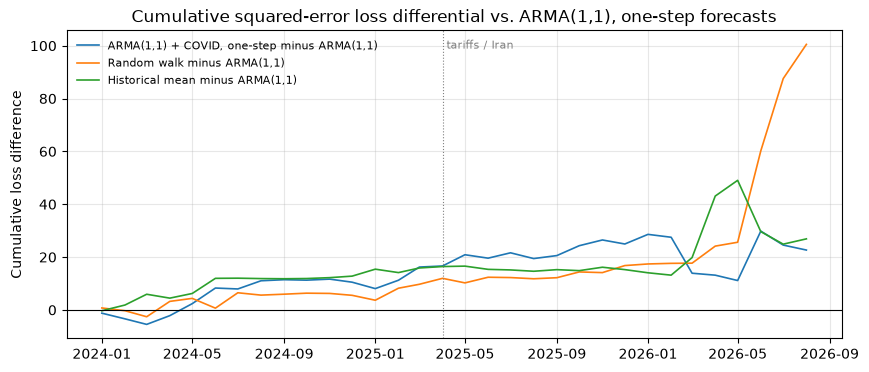

In [187]:
# Diebold-Mariano test (S5, T6.4), squared-error loss, each forecast vs. the selected
# ARMA(1,1) one-step forecast. d_t = e_other^2 - e_ARMA^2; mean(d) > 0 means ARMA(1,1) is
# more accurate. One-step forecasts -> h = 1, so the long-run variance needs no HAC lags.
# Harvey-Leybourne-Newbold small-sample correction (T = 32), compared with a t(T-1).
def diebold_mariano(e_other, e_base, h=1):
    d = e_other ** 2 - e_base ** 2
    T = len(d)
    dm_stat = d.mean() / np.sqrt(d.var(ddof=0) / T)
    hln = dm_stat * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return {"Mean loss diff": d.mean(), "DM (HLN)": hln, "p-value": 2 * stats.t.sf(abs(hln), T - 1)}


base = "ARMA(1,1), one-step"
dm_table = pd.DataFrame({
    name: diebold_mariano(errors[name], errors[base]) for name in errors if name != base
}).T
dm_table["Verdict (5%)"] = np.where(
    dm_table["p-value"] >= alpha, "No significant difference",
    np.where(dm_table["Mean loss diff"] > 0, "ARMA(1,1) better", "ARMA(1,1) worse"))
display(dm_table.style.format({"Mean loss diff": "{:.3f}", "DM (HLN)": "{:.3f}", "p-value": "{:.3f}"}))

# Interval calibration: share of actual values inside the 95% intervals (nominal 0.95)
coverage = pd.DataFrame({
    f"{name}, {kind}": {"95% coverage": ((actual >= f["mean_ci_lower"]) & (actual <= f["mean_ci_upper"])).mean(),
                        "Average width": (f["mean_ci_upper"] - f["mean_ci_lower"]).mean()}
    for kind, fcs in (("one-step", one_step), ("multi-step", multi)) for name, f in fcs.items()
}).T
display(coverage.style.format({"95% coverage": "{:.2f}", "Average width": "{:.1f}"}))

# Cumulative loss differential (S5): rising line = ARMA(1,1) pulling ahead of the competitor
cum = pd.DataFrame({name: (errors[name] ** 2 - errors[base] ** 2).cumsum()
                    for name in ("ARMA(1,1) + COVID, one-step", "Random walk", "Historical mean")})
fig, ax = plt.subplots(figsize=(10, 4))
for name in cum:
    ax.plot(cum.index, cum[name], lw=1.2, label=f"{name} minus ARMA(1,1)")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(pd.Timestamp(tariff), color="gray", ls=":", lw=0.8)
ax.text(pd.Timestamp(tariff), 0.97, " tariffs / Iran", transform=ax.get_xaxis_transform(),
        va="top", fontsize=8, color="gray")
ax.set_title("Cumulative squared-error loss differential vs. ARMA(1,1), one-step forecasts")
ax.set_ylabel("Cumulative loss difference")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.3)
plt.show()